# Musanga — NB02 V4.009 | Full spatial CV, unified 50%-overlap inference

**Same NB02 workflow and existing verified V4.007 training checkpoints.** V4.009 integrates 256 × 256 pixel / 128-pixel-stride, globally mosaic-aligned **Hann-blended probability inference** into BOTH main evaluation sections (all 78 field plots, 76 RGB-evaluable, and all 34 exhaustive circles). Not just a diagnostic patch. Plot-level and circle-level metrics, probability figures, paired old-vs-new results, and MOS examples are saved separately to `Outputs/v4/02_rgb_unet_field78_v4_009_evaluation/`.

**Run all code blocks top-to-bottom. There is NO training cell.** The three frozen V4.007 model checkpoints are loaded read-only from `Outputs/v4/02_rgb_unet_field78_v4_007_full/`; the notebook writes only to its separate V4.009 inference-evaluation directory.

`VERSION='V4.007'` reflects the **trained model version**, while `INFERENCE_VERSION='V4.009'` reflects the **evaluation method**. No changes to original training annotations, folds, trained weights, or V4.007 metrics.

**Publication-ready evaluation:** The integrated report includes cover R², Pearson r, MAE, RMSE, bias, RPD, RPIQ, calibration slope/intercept; per-unit and pooled precision, recall, specificity, F1, IoU, balanced accuracy, prevalence and Brier; and 512-bin approximate ROC-AUC and average precision. Per-plot/per-circle and all/site/fold/site-fold CSVs plus probability histograms are preserved. ROC-AUC/AP are approximate due to 512 probability bins; zero-positive unit metrics are recorded as undefined rather than 0. Full evaluation must be rerun to produce the new probability histograms, but training is never rerun.


In [10]:
# 00 — Environment, frozen inputs and run settings
%pip -q install geopandas pyogrio shapely rasterio scipy scikit-learn torch matplotlib segmentation-models-pytorch
from pathlib import Path
import json, math, random, copy, time, warnings, os
import numpy as np, pandas as pd, geopandas as gpd, rasterio
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
from shapely.ops import unary_union
from shapely import make_valid
from shapely.strtree import STRtree
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
DRIVE=Path('/content/drive/MyDrive')
ROOT=DRIVE/'Colab Notebooks/Musanga/Final'
assert ROOT.is_dir(), ROOT
DATA=ROOT/'Data'
REF_DIR=ROOT/'Outputs/v4/01_reference_field78_combined'
CONTRACT=json.loads((REF_DIR/'01_field78_reference_contract.json').read_text())
assert CONTRACT['schema']=='musanga_v4_field78_combined_reference_final_2',CONTRACT['schema']
NB00=json.loads(Path(CONTRACT['input_manifest']).read_text())
assert NB00['n_field_plots']==78
SPLITS=pd.read_csv(CONTRACT['cv_manifest'])
assert len(SPLITS)==9096,(len(SPLITS),'Expected 3032 unique windows × 3 folds; changed source audit?')
K=['cv_fold','mosaic','row','col','width','height']
assert not SPLITS.duplicated(K).any()
assert SPLITS.groupby('cv_fold').size().eq(3032).all()
assert set(SPLITS.split).issubset({'train','val','excluded_spatial_guard','excluded_no_validation_pixels'})
PLOTS=gpd.read_file(NB00['field_support_qa']).to_crs('EPSG:32635')
PLOT_FOLDS=pd.read_csv(CONTRACT['folds_csv'])
assert len(PLOTS)==len(PLOT_FOLDS)==78 and PLOT_FOLDS.source_id.is_unique
PLOTS=PLOTS.merge(PLOT_FOLDS[['source_id','site_key','cv_fold']],left_on='Plot_name',right_on='source_id',validate='one_to_one')
CIRCLE_FOLDS=pd.read_csv(REF_DIR/'01_field78_circle_folds.csv')
# Adjustable, deterministic experiment settings
SMOKE_TEST=False           # FIXED FULL RUN ONLY; no smoke option
RUN_FOLDS=[0,1,2]         # FIXED all three spatial folds
SEED=20261113
CHIP=256                   # 256 native pixels; no spatial downsampling
BATCH_SIZE=8
EPOCHS=25
STEPS_PER_EPOCH=100
EVAL_BATCH_SIZE=8  # batched exhaustive held-out inference, mosaic handle opened once
LEARNING_RATE=2e-4
PATIENCE=4
POSITIVE_SAMPLE_BOOST=2.5
MAX_VAL_WINDOWS_PER_SITE=35  # early-stopping cache only; FINAL evaluation is uncapped
MAX_TRAIN_WINDOWS_PER_SITE=180
NUM_WORKERS=0              # Google Drive + GDAL: safest in Colab
OUT=ROOT/'Outputs/v4/02_rgb_unet_field78_v4_007_full'
OUT.mkdir(parents=True,exist_ok=True)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type=='cuda', 'V3_1 used GPU; select Colab GPU runtime before training'
print('Device:',DEVICE,'| NESTED FULL SPATIAL CV')
print('Final manifest:',CONTRACT['cv_manifest'])
print('Observed window splits:');display(SPLITS.groupby(['cv_fold','site','split']).size().unstack(fill_value=0))

# Canonical immutable numbered experiment; no shared output with earlier experiments.
VERSION='V4.007'
assert SMOKE_TEST is False and RUN_FOLDS==[0,1,2]
assert EPOCHS==25 and STEPS_PER_EPOCH==100
assert MAX_TRAIN_WINDOWS_PER_SITE==180 and MAX_VAL_WINDOWS_PER_SITE==35
assert OUT.name=='02_rgb_unet_field78_v4_007_full',OUT
CHECKPOINTS={fold:OUT/f'NB02_V4_007_fold{fold}_best.pt' for fold in RUN_FOLDS}
print('STRICT FULL MODEL RUN:',VERSION,'\nOUTPUT:',OUT)
print('FOLD CHECKPOINTS:',{f:str(p) for f,p in CHECKPOINTS.items()})

N_BINS=512 # used by secondary complete-circle metrics if plot evaluation is skipped

INNER_BLOCK_PX=2048
INNER_GUARD_PX=256
INNER_VAL_FRACTION=.20
SOURCE_CODES={0:'unknown',1:'partial_crown',2:'exhaustive_circle',3:'exhaustive_plot'}

# V4.007 reuses ONLY V4.003 source-labelled chip cache bytes when exact
# manifest/input fingerprint matches; no model weights are transferred.
READ_ONLY_CACHE_V003=ROOT/'Outputs/v4/02_rgb_unet_field78_v4_003_full/chip_cache'
INNER_SELECTION_SOURCES=(2,3)   # exhaustive circles and plots ONLY
TRAINING_SOURCES=(1,2,3)         # individual positive/negative crowns training ONLY
assert VERSION=='V4.007' and OUT.name=='02_rgb_unet_field78_v4_007_full'

import gc,resource
def memory_snapshot(tag):
    print('RAM diagnostic',tag,'max_RSS_GB',round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024**2,2),flush=True)


Device: cuda | NESTED FULL SPATIAL CV
Final manifest: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/01_reference_field78_combined/01_field78_cv_window_manifest_FINAL.csv
Observed window splits:


split             excluded_spatial_guard  train  val
cv_fold site                                        
0       Baego                         31    330   12
        MOS                           54    661   33
        Yangambi                     375    656  299
        Yoko                         139    416   26
1       Baego                         21    344    8
        MOS                           42    667   39
        Yangambi                      70   1132  128
        Yoko                          49    508   24
2       Baego                         22    343    8
        MOS                           14    686   48
        Yangambi                      83   1107  140
        Yoko                          55    501   25

STRICT FULL MODEL RUN: V4.007 
OUTPUT: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/02_rgb_unet_field78_v4_007_full
FOLD CHECKPOINTS: {0: '/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/02_rgb_unet_field78_v4_007_full/NB02_V4_007_fold0_best.pt', 1: '/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/02_rgb_unet_field78_v4_007_full/NB02_V4_007_fold1_best.pt', 2: '/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/02_rgb_unet_field78_v4_007_full/NB02_V4_007_fold2_best.pt'}


## 01 — Spatial references, mosaics and strict fold assignments

In [11]:
# 01 — Geometry references and fast spatial indexes
CROWNS=gpd.read_file(NB00['exhaustive_plot_crowns']).to_crs('EPSG:32635')
CIRCLE_ROI=gpd.read_file(NB00['circle_complete_roi']).to_crs('EPSG:32635')
CIRCLE_POS=gpd.read_file(NB00['circle_positive_crowns']).to_crs('EPSG:32635')
assert len(CROWNS)==3324 and len(CIRCLE_ROI)==34
assert 'Class_ID' in CROWNS
def polygons(g):
    if g is None or g.is_empty:return []
    if g.geom_type=='Polygon':return [g]
    if g.geom_type=='MultiPolygon':return list(g.geoms)
    return [a for v in getattr(g,'geoms',[]) for a in polygons(v)]
def fix(g):
    if g is None or g.is_empty:return None
    if g.is_valid:return g
    q=unary_union(polygons(make_valid(g)))
    if q.is_empty or not q.is_valid:return None
    if abs(q.area-g.area)/max(q.area,g.area,1e-12)>.05:return None
    return q
CROWNS.geometry=[fix(g) for g in CROWNS.geometry]
assert CROWNS.geometry.notna().all(),'Unrepaired plot crowns; see NB00 QA'
CIRCLE_ROI.geometry=[fix(g) for g in CIRCLE_ROI.geometry]
CIRCLE_POS.geometry=[fix(g) for g in CIRCLE_POS.geometry]
assert CIRCLE_ROI.geometry.notna().all()
CIRCLE_ROI['circle_id']=np.arange(len(CIRCLE_ROI))
CIRCLE_ROI=CIRCLE_ROI.merge(CIRCLE_FOLDS[['circle_id','site_key','cv_fold',
    'cross_fold_plot_intersection']],on='circle_id',validate='one_to_one')
CROWN_POS=list(CROWNS.loc[pd.to_numeric(CROWNS.Class_ID).eq(1)].geometry)
CROWN_NEG=list(CROWNS.loc[~pd.to_numeric(CROWNS.Class_ID).eq(1)].geometry)
CIRCLE_POS_GEOMS=[g for g in CIRCLE_POS.geometry if g is not None and not g.is_empty]
# Partial site references from old V3_1 audit, same positive=1 / other known class negative.
PARTIAL={}
for site,path in NB00['partial_site_crowns'].items():
    d=gpd.read_file(path).to_crs('EPSG:32635')
    d.geometry=[fix(g) for g in d.geometry]
    d=d[d.geometry.notna() & pd.to_numeric(d.Class_ID,errors='coerce').notna()]
    PARTIAL[site]=d
P_GEOMS=list(PLOTS.geometry)
C_GEOMS=list(CIRCLE_ROI.geometry)
P_T=STRtree(P_GEOMS); C_T=STRtree(C_GEOMS)
CP_T=STRtree(CROWN_POS);CN_T=STRtree(CROWN_NEG)
KPOS_T=STRtree(CIRCLE_POS_GEOMS)
PARTIAL_T={}
for site,d in PARTIAL.items():
    pos=list(d.loc[pd.to_numeric(d.Class_ID).eq(1)].geometry)
    neg=list(d.loc[~pd.to_numeric(d.Class_ID).eq(1)].geometry)
    PARTIAL_T[site]=(pos,neg,STRtree(pos) if pos else None,
                     STRtree(neg) if neg else None)
RGB={}
for item in sorted(SPLITS.mosaic.unique()):
    q=DATA/'Ortho_RGB'/item
    assert q.exists(),q
    with rasterio.open(q) as ds:
        assert ds.crs.to_epsg()==32635,(item,ds.crs)
        assert ds.count>=3,(item,ds.count)
        RGB[item]=dict(path=str(q),transform=ds.transform,site=next(
            iter(SPLITS.loc[SPLITS.mosaic==item,'site'].unique())))
# NOTE: ROI.shp is the authoritative six-mosaic modelling ROI (not the old
# circle-only support). The validation/labelled field plot is also required.
ROIS=gpd.read_file(DATA/'Ortho_RGB/ROI.shp').to_crs('EPSG:32635')
ROI_GEOMS=list(ROIS.geometry)
ROI_T=STRtree(ROI_GEOMS)
print('Loaded',len(PLOTS),'plots,',len(CIRCLE_ROI),'circles,',
      len(CROWN_POS),'Musanga plot crowns and',len(CIRCLE_POS_GEOMS),'circle crowns')


Loaded 78 plots, 34 circles, 700 Musanga plot crowns and 635 circle crowns


In [12]:
# 02 — Rasterize strict plot > circle > partial supervision on demand
# Geometry-level spatial queries restrict operations to the local 256px footprint.
def geom_hits(tree,geoms,ext):
    if tree is None:return []
    return [geoms[int(i)] for i in tree.query(ext,predicate='intersects')]
_ACTIVE_RASTER=None
_ACTIVE_NAME=None
def rgb_window(raster_path,win):
    from contextlib import nullcontext
    name=Path(raster_path).name
    ds_context=nullcontext(_ACTIVE_RASTER) if (_ACTIVE_RASTER is not None and _ACTIVE_NAME==name) else rasterio.open(raster_path)
    with ds_context as ds:
        a=ds.read([1,2,3],window=win,masked=True)
        valid=ds.dataset_mask(window=win)>0
        valid &= ~np.ma.getmaskarray(a).any(axis=0)
        x=np.asarray(a.filled(0),dtype=np.float32)
        # RGB products expected standard 8-bit; prevent silent incorrect scaling.
        if np.issubdtype(np.dtype(ds.dtypes[0]),np.integer) and np.dtype(ds.dtypes[0]).itemsize==1:
            x=x/255.
        else:
            raise RuntimeError(f'Non-uint8 RGB {ds.dtypes}: {raster_path}; define radiometric scaling first')
    return x,np.asarray(valid,bool)
def supervision(mosaic,win,fold,role,with_source=False):
    site=RGB[mosaic]['site'];t=RGB[mosaic]['transform']
    h,w=int(win.height),int(win.width)
    affine=rasterio.windows.transform(win,t)
    footprint=box(*rasterio.windows.bounds(win,t))
    def burn(gs):
        return rasterize(((g,1) for g in gs if g is not None and not g.is_empty),
            out_shape=(h,w),transform=affine,fill=0,dtype='uint8').astype(bool) if gs else np.zeros((h,w),bool)
    roi=burn(geom_hits(ROI_T,ROI_GEOMS,footprint))
    pids=[int(i) for i in P_T.query(footprint,predicate='intersects')
          if PLOTS.iloc[int(i)].site_key==site and
          (role=='train' and PLOTS.iloc[int(i)].cv_fold!=fold or
           role=='val' and PLOTS.iloc[int(i)].cv_fold==fold)]
    plot=burn([P_GEOMS[i] for i in pids])
    # Every other fold's field plot is out of scope for val; all exhaustive
    # plot geometries (not only selected) override circle labels.
    allplot=burn([P_GEOMS[int(i)] for i in P_T.query(footprint,predicate='intersects')
                  if PLOTS.iloc[int(i)].site_key==site])
    cids=[int(i) for i in C_T.query(footprint,predicate='intersects')
          if CIRCLE_ROI.iloc[int(i)].site_key==site and
          not CIRCLE_ROI.iloc[int(i)].cross_fold_plot_intersection and
          (role=='train' and CIRCLE_ROI.iloc[int(i)].cv_fold!=fold)]
    circle=burn([C_GEOMS[i] for i in cids])&~allplot if role=='train' else np.zeros((h,w),bool)
    # Partial crowns must NEVER relabel any exhaustive circle, including
    # an outer-held-out circle. Train circles retain exclusive authority.
    allcircle=burn([C_GEOMS[int(i)] for i in C_T.query(footprint,predicate='intersects')
        if CIRCLE_ROI.iloc[int(i)].site_key==site])
    posplot=burn(geom_hits(CP_T,CROWN_POS,footprint))&plot
    negplot=burn(geom_hits(CN_T,CROWN_NEG,footprint))&plot
    poscircle=burn(geom_hits(KPOS_T,CIRCLE_POS_GEOMS,footprint))&circle
    part_pos=np.zeros((h,w),bool);part_neg=np.zeros((h,w),bool)
    if role=='train':
        positives,negatives,tp,tn=PARTIAL_T[site]
        part_pos=burn(geom_hits(tp,positives,footprint))&~allplot&~allcircle
        part_neg=burn(geom_hits(tn,negatives,footprint))&~allplot&~allcircle
    source=np.zeros((h,w),dtype=np.uint8)
    source[part_pos|part_neg]=1
    source[circle]=2
    source[plot]=3
    target=(posplot|poscircle|part_pos)
    conflicting=(posplot&negplot)|(part_pos&part_neg)
    weight=roi&(plot|circle|part_pos|part_neg)&~conflicting
    source[~weight.astype(bool)]=0
    assert not np.any((source==0)&(weight>0))
    return (target.astype(np.float32),weight.astype(np.float32),plot.astype(bool),source) if with_source else (target.astype(np.float32),weight.astype(np.float32),plot.astype(bool))
def get_chip(mosaic,win,fold,role):
    x,rgbvalid=rgb_window(RGB[mosaic]['path'],win)
    y,w,plot,source=supervision(mosaic,win,fold,role,with_source=True)
    w*=rgbvalid.astype(np.float32)
    source[~rgbvalid]=0
    return x,y,w,plot,source
print('Prepared lazy RGB + spatially strict masks. No imagery loaded globally.')


Prepared lazy RGB + spatially strict masks. No imagery loaded globally.


## 03 — ResNet18 U-Net architecture (model loading only)

In [13]:
# 05 — Restore the working V3_1 ResNet18 U-Net + masked BCE, AMP in training
import segmentation_models_pytorch as smp
import torch.nn.functional as F
class ResNet18UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=smp.Unet(encoder_name='resnet18',encoder_weights='imagenet',
            in_channels=3,classes=1)
    def forward(self,x):return self.net(x)  # B,1,H,W
AMP=DEVICE.type=='cuda'
print('Model definition ready — inference only.')


Model definition ready — inference only.


## 05 — Verify V4.007 full checkpoints (also entry point for evaluation-only restarts)

In [14]:
# VERIFY FROZEN CHECKPOINTS — inference only. No training or checkpoint writes.
assert VERSION=='V4.007' and RUN_FOLDS==[0,1,2] and SMOKE_TEST is False
for fold,path in CHECKPOINTS.items():
    assert path.is_file(),('Missing V4.007 full checkpoint',fold,path)
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck.get('version')==VERSION and ck.get('smoke') is False
    assert ck.get('fold')==fold and ck.get('architecture')=='smp_unet_resnet18_imagenet'
    assert ck.get('n_train_chips',0)>=100,('Insufficient full training chips',fold,ck.get('n_train_chips'))
    assert ck.get('training_epochs_configured')==25
    assert ck.get('training_steps_configured')==100
    assert ck.get('selection_protocol')=='inner_exhaustive_only_blocked_plus_unit_guard'
    assert ck.get('source_loss')=='V3_1_masked_pixel_BCE'
    assert ck.get('epoch',0)>=2,('Early stopping did not complete minimum training',fold)
    print(f'VERIFIED {VERSION} FOLD {fold}: epoch={ck["epoch"]}, '
          f'train_chips={ck["n_train_chips"]}, val_chips={ck["n_val_chips"]}, '
          f'loss={ck["val_loss"]:.4f}, file={path.name}')
    del ck
print('ALL THREE FULL CHECKPOINTS VERIFIED — safe to evaluate.')


VERIFIED V4.007 FOLD 0: epoch=7, train_chips=446, val_chips=56, loss=0.2111, file=NB02_V4_007_fold0_best.pt
VERIFIED V4.007 FOLD 1: epoch=3, train_chips=366, val_chips=63, loss=0.3074, file=NB02_V4_007_fold1_best.pt
VERIFIED V4.007 FOLD 2: epoch=11, train_chips=407, val_chips=73, loss=0.2729, file=NB02_V4_007_fold2_best.pt
ALL THREE FULL CHECKPOINTS VERIFIED — safe to evaluate.


## 06 — V4.009 | Canonical overlapping inference engine (all evaluations)


In [15]:
# GLOBAL 128 px grid, 256 px tiles, Hann blend — model probabilities, not hard masks.
# Every output core is evaluated ONCE; the outer halo supplies inference context.
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from pyproj import Transformer
import gc

INFERENCE_VERSION='V4.009'
EVAL_OUT=ROOT/'Outputs/v4/02_rgb_unet_field78_v4_009_evaluation'
EVAL_OUT.mkdir(parents=True,exist_ok=True)
V009_TILE=256
V009_STRIDE=128
assert VERSION=='V4.007' and INFERENCE_VERSION=='V4.009'
assert V009_TILE==CHIP and V009_STRIDE==CHIP//2
for fold,p in CHECKPOINTS.items():
    assert p.is_file(),('Missing frozen V4.007 checkpoint',fold,p)
FOLDS=[0,1,2]
PROBABILITY_BINS=512
PLOT_PROB_HISTS={}
CIRCLE_PROB_HISTS={}
EXAMPLE_IDS={3,9,29,26}
SAVE_EXAMPLE_FIGURES=True

def load_frozen_model(fold):
    ck=torch.load(CHECKPOINTS[int(fold)],map_location='cpu',weights_only=False)
    assert ck['version']=='V4.007' and ck['fold']==int(fold) and not ck['smoke']
    assert ck.get('source_loss')=='V3_1_masked_pixel_BCE'
    m=ResNet18UNet().to(DEVICE)
    m.load_state_dict(ck['model'])
    del ck
    m.eval()
    return m

def burn(gs,ds,win):
    if not gs:return np.zeros((int(win.height),int(win.width)),dtype=bool)
    return rasterize(((g,1) for g in gs if g is not None and not g.is_empty),
        out_shape=(int(win.height),int(win.width)),
        transform=ds.window_transform(win),fill=0,dtype='uint8').astype(bool)

# Deliberately nonzero edge weight to guarantee complete support at raster limits.
hann=np.hanning(V009_TILE+2)[1:-1].astype(np.float32)
WEIGHT=np.maximum(np.outer(hann,hann),0.01).astype(np.float32)
WEIGHT/=WEIGHT.max()

def blended_window(ds,model,win):
    """Blended P(Musanga) for a core window, anchored to entire mosaic pixel grid.

    Loads only bounded core+halo RGB. No per-tile compressed-cache calls, no
    complete-orthomosaic arrays, no thresholding before probability blending.
    """
    core_r=int(win.row_off);core_c=int(win.col_off)
    h=int(win.height);w=int(win.width)
    assert h>0 and w>0 and core_r>=0 and core_c>=0
    assert core_r+h<=ds.height and core_c+w<=ds.width
    halo=V009_TILE
    top=max(0,core_r-halo);left=max(0,core_c-halo)
    bottom=min(ds.height,core_r+h+halo);right=min(ds.width,core_c+w+halo)
    full=Window(left,top,right-left,bottom-top)
    raw=ds.read([1,2,3],window=full)
    assert ds.dtypes[0]=='uint8',(ds.name,ds.dtypes)
    rgb=raw.astype(np.float32)/255.
    H,W=rgb.shape[1:]
    acc=np.zeros((H,W),np.float32)
    wt=np.zeros((H,W),np.float32)
    # Every contributing patch aligned to global origin at steps of 128 px.
    r0=((top-V009_TILE+V009_STRIDE)//V009_STRIDE)*V009_STRIDE
    c0=((left-V009_TILE+V009_STRIDE)//V009_STRIDE)*V009_STRIDE
    with torch.inference_mode():
        for gr in range(r0,bottom,V009_STRIDE):
            for gc0 in range(c0,right,V009_STRIDE):
                ar=max(top,gr);br=min(bottom,gr+V009_TILE)
                ac=max(left,gc0);bc=min(right,gc0+V009_TILE)
                if br<=ar or bc<=ac:continue
                patch=np.zeros((3,V009_TILE,V009_TILE),np.float32)
                patch[:,ar-gr:br-gr,ac-gc0:bc-gc0]=rgb[:,ar-top:br-top,ac-left:bc-left]
                xx=torch.from_numpy(patch[None]).to(DEVICE)
                with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=AMP):
                    p=torch.sigmoid(model(xx))[0,0].float().cpu().numpy()
                z=WEIGHT[ar-gr:br-gr,ac-gc0:bc-gc0]
                acc[ar-top:br-top,ac-left:bc-left]+=p[ar-gr:br-gr,ac-gc0:bc-gc0]*z
                wt[ar-top:br-top,ac-left:bc-left]+=z
    oy=core_r-top;ox=core_c-left
    sl=np.s_[oy:oy+h,ox:ox+w]
    assert np.all(wt[sl]>0),(ds.name,win,'uncovered prediction pixels')
    return (acc[sl]/wt[sl]).astype(np.float32)

def collect_metrics(p,truth,support):
    assert support.any()
    pred=p>=0.5
    tp=int((pred&truth&support).sum());fp=int((pred&~truth&support).sum())
    fn=int((~pred&truth&support).sum());tn=int((~pred&~truth&support).sum())
    n=int(support.sum())
    return dict(tp=tp,fp=fp,fn=fn,tn=tn,n=n,
        observed_cover_pct=100*(tp+fn)/n,
        predicted_cover_pct=100*(tp+fp)/n,
        predicted_probability_pct=100*float(p[support].mean()),
        bias_pp=100*(fp-fn)/n,
        Brier=float(np.mean((p[support]-truth[support])**2)),
        **confusion_statistics(tp,fp,fn,tn))

def _figure(cid,mosaic,ds,win,rgb,truth,support,prob,scores):
    ds_h,ds_w=truth.shape
    step=max(1,int(np.ceil(max(ds_h,ds_w)/950)))
    sl=np.s_[::step,::step]
    view=rgb.transpose(1,2,0)[sl]
    y=truth[sl];supp=support[sl];p=prob[sl]
    cls=p>=0.5
    fig,axs=plt.subplots(1,5,figsize=(20,4.7),layout='constrained')
    axs[0].imshow(view);axs[0].set_title('RGB')
    overlay=view.copy();overlay[y&supp]=.45*overlay[y&supp]+.55*np.array([1,.1,.1])
    axs[1].imshow(np.clip(overlay,0,1));axs[1].set_title('Exhaustive reference · red')
    axs[2].imshow(view)
    a=axs[2].imshow(np.ma.masked_where(~supp,p),cmap='magma',vmin=0,vmax=1,alpha=.90)
    axs[2].set_title('Blended probability P(Musanga)')
    fig.colorbar(a,ax=axs[2],fraction=.045,pad=.02)
    overlay=view.copy();overlay[cls&supp]=.45*overlay[cls&supp]+.55*np.array([.1,1,1])
    axs[3].imshow(np.clip(overlay,0,1));axs[3].set_title('Blended threshold 0.5 · cyan')
    err=view.copy()
    for mask,color in [(cls&y&supp,[.1,1,.1]),(cls&~y&supp,[1,.1,.1]),(~cls&y&supp,[.1,.35,1])]:
        err[mask]=.3*err[mask]+.7*np.array(color)
    axs[4].imshow(np.clip(err,0,1));axs[4].set_title('TP green · FP red · FN blue')
    for ax in axs:ax.axis('off')
    fig.suptitle(f'{mosaic} | circle {cid} | observed {scores["observed_cover_pct"]:.1f}% '
                 f'→ blended {scores["predicted_cover_pct"]:.1f}% | '
                 f'bias {scores["bias_pp"]:+.1f} pp',fontsize=12)
    fig.savefig(EVAL_OUT/f'circle_{cid:02d}_blended_probability.png',dpi=160,bbox_inches='tight')
    plt.show();plt.close(fig)
def coverage_summary(g):
    """Site-pooled cover metrics and mean per-circle/plot pixel statistics."""
    yy=g.observed_cover_pct.to_numpy(float)
    pp=g.predicted_cover_pct.to_numpy(float)
    return pd.Series(dict(n=len(g),
        R2=r2_score(yy,pp) if len(g)>1 else np.nan,
        MAE_pp=np.mean(np.abs(pp-yy)),
        RMSE_pp=np.sqrt(np.mean((pp-yy)**2)),
        bias_pp=np.mean(pp-yy),
        mean_pixel_F1=g.pixel_F1.mean(),
        mean_pixel_IoU=g.pixel_IoU.mean(),
        mean_Brier=g.Brier.mean()))


def probability_histogram(probabilities,truth):
    """512-bin streaming histogram; preserves all eligible pixels but no huge arrays."""
    p=np.asarray(probabilities,dtype=np.float32).ravel()
    y=np.asarray(truth,dtype=bool).ravel()
    assert len(p)==len(y) and np.isfinite(p).all()
    b=np.minimum((np.clip(p,0.,1.)*PROBABILITY_BINS).astype(np.int32),
                 PROBABILITY_BINS-1)
    total=np.bincount(b,minlength=PROBABILITY_BINS).astype(np.int64)
    positive=np.bincount(b,weights=y.astype(np.int64),
                         minlength=PROBABILITY_BINS).astype(np.int64)
    assert positive.sum()==int(y.sum())
    return total,positive

def rank_scores(total,positive):
    """Approximate ROC-AUC / AP using 512 probability bins, with ties accounted for."""
    total=np.asarray(total,dtype=np.float64)
    pos=np.asarray(positive,dtype=np.float64)
    neg=total-pos
    npos=float(pos.sum());nneg=float(neg.sum())
    if npos==0 or nneg==0:return np.nan,np.nan
    auc=float(np.dot(pos,np.cumsum(neg)-.5*neg)/(npos*nneg))
    p_desc=pos[::-1];n_desc=neg[::-1]
    recall_step=p_desc/npos
    precision=np.cumsum(p_desc)/np.maximum(1.,np.cumsum(p_desc+n_desc))
    ap=float(np.dot(recall_step,precision))
    return auc,ap

def confusion_statistics(tp,fp,fn,tn):
    tp,fp,fn,tn=[int(z) for z in (tp,fp,fn,tn)]
    pos=tp+fn;neg=tn+fp;predpos=tp+fp;den=tp+fp+fn
    prec=tp/predpos if predpos else np.nan
    rec=tp/pos if pos else np.nan
    spec=tn/neg if neg else np.nan
    return dict(pixel_precision=prec,pixel_recall=rec,
        pixel_specificity=spec,
        pixel_balanced_accuracy=(rec+spec)/2 if np.isfinite(rec) and np.isfinite(spec) else np.nan,
        pixel_F1=2*tp/(2*tp+fp+fn) if pos and (2*tp+fp+fn) else np.nan,
        pixel_IoU=tp/den if pos and den else np.nan,
        pixel_prevalence=pos/(pos+neg) if pos+neg else np.nan)

def complete_cover_summary(g,hists=None,unit_key=None):
    """Macro cover skill, macro pixel stats, pooled pixel stats, binned probability scores."""
    yy=g.observed_cover_pct.to_numpy(float)
    pp=g.predicted_cover_pct.to_numpy(float)
    valid=np.isfinite(yy)&np.isfinite(pp)
    yy=yy[valid];pp=pp[valid]
    assert len(yy)>0
    diff=pp-yy
    rmse=float(np.sqrt(np.mean(diff**2)))
    sd=float(np.std(yy,ddof=1)) if len(yy)>1 else np.nan
    iqr=float(np.percentile(yy,75)-np.percentile(yy,25)) if len(yy)>1 else np.nan
    r=float(np.corrcoef(yy,pp)[0,1]) if len(yy)>1 and np.std(yy)>1e-10 and np.std(pp)>1e-10 else np.nan
    slope=float(np.cov(yy,pp,ddof=0)[0,1]/np.var(yy)) if len(yy)>1 and np.var(yy)>1e-15 else np.nan
    intercept=float(np.mean(pp)-slope*np.mean(yy)) if np.isfinite(slope) else np.nan
    tp=int(g.tp.sum());fp=int(g.fp.sum());fn=int(g.fn.sum());tn=int(g.tn.sum())
    pooled=confusion_statistics(tp,fp,fn,tn)
    result=dict(n_units=len(yy),
        cover_R2=float(r2_score(yy,pp)) if len(yy)>1 and np.var(yy)>1e-15 else np.nan,
        cover_Pearson_r=r,cover_MAE_pp=float(np.mean(abs(diff))),
        cover_RMSE_pp=rmse,cover_bias_pp=float(np.mean(diff)),
        cover_RPD=sd/rmse if rmse>0 else np.nan,
        cover_RPIQ=iqr/rmse if rmse>0 else np.nan,
        calibration_slope=slope,calibration_intercept_pp=intercept,
        macro_pixel_F1=float(g.pixel_F1.mean()),macro_pixel_IoU=float(g.pixel_IoU.mean()),
        macro_pixel_precision=float(g.pixel_precision.mean()),
        macro_pixel_recall=float(g.pixel_recall.mean()),
        macro_pixel_specificity=float(g.pixel_specificity.mean()),
        macro_pixel_balanced_accuracy=float(g.pixel_balanced_accuracy.mean()),
        mean_Brier=float(g.Brier.mean()),
        pooled_Brier=float(np.average(g.Brier,weights=g.n)) if int(g.n.sum()) else np.nan,
        pooled_tp=tp,pooled_fp=fp,pooled_fn=fn,pooled_tn=tn)
    result.update({'pooled_'+k:v for k,v in pooled.items()})
    if hists is not None:
        assert unit_key is not None
        selected=[hists[key] for key in g[unit_key] if key in hists]
        if selected:
            total=np.sum([x[0] for x in selected],axis=0)
            positive=np.sum([x[1] for x in selected],axis=0)
            assert int(total.sum())==int(g.n.sum()),'Histogram and support totals disagree'
            auc,ap=rank_scores(total,positive)
        else:
            auc,ap=np.nan,np.nan
        result.update(pixel_ROC_AUC_512bins=auc,pixel_average_precision_512bins=ap)
    return pd.Series(result)

def metrics_table(df,kind,hists,key):
    eligible=df.loc[df.n.gt(0)].copy()
    summaries=[dict(grouping='ALL',site='ALL',fold='ALL',
                    **complete_cover_summary(eligible,hists,key).to_dict())]
    for site,g in eligible.groupby('site'):
        summaries.append(dict(grouping='site',site=site,fold='ALL',
                     **complete_cover_summary(g,hists,key).to_dict()))
    for fold,g in eligible.groupby('fold'):
        summaries.append(dict(grouping='fold',site='ALL',fold=int(fold),
                     **complete_cover_summary(g,hists,key).to_dict()))
    for (fold,site),g in eligible.groupby(['fold','site']):
        summaries.append(dict(grouping='site_fold',site=site,fold=int(fold),
                     **complete_cover_summary(g,hists,key).to_dict()))
    out=pd.DataFrame(summaries)
    out.to_csv(EVAL_OUT/f'V4_009_{kind}_complete_metric_report.csv',index=False)
    return out

def save_histograms(path,hists):
    arrays={}
    for key,(tot,pos) in hists.items():
        safe=str(key).replace('/','_').replace(' ','_')
        arrays[safe+'_total']=tot
        arrays[safe+'_positive']=pos
    np.savez_compressed(path,**arrays)

print('READY — V4.009 unified 50% overlap + smooth blend, models read-only')


READY — V4.009 unified 50% overlap + smooth blend, models read-only


## 07 — Full held-out field-plot evaluation: 78 plots, 76 RGB-evaluable

All held-out validation windows use **exactly the same 50% overlap and probability blending** as the circle evaluation. Original V4.007 non-overlap results are not overwritten.

Includes 512-bin probability histograms and complete per-plot/pooled pixel metrics, saved in the V4.009 output folder.


In [16]:
# Plot evaluation uses every unmodified outer 'val' manifest window (no sampling).
# Buffered overlapping inference is run only over selected validation windows;
# label masks remain strictly inside each valid held-out plot and ROI.
PLOT_ROWS=[]
for fold in FOLDS:
    model=load_frozen_model(fold)
    state={}
    for pl in PLOTS.loc[PLOTS.cv_fold.eq(fold)].itertuples(index=False):
        state[str(pl.Plot_name)]=dict(tp=0,fp=0,fn=0,tn=0,n=0,sum_prob=0.,sum_brier=0.,
                                     site=pl.site_key,prob_total=np.zeros(PROBABILITY_BINS,dtype=np.int64),
                                     prob_pos=np.zeros(PROBABILITY_BINS,dtype=np.int64))
    rows=SPLITS.loc[(SPLITS.cv_fold==fold)&SPLITS.split.eq('val')]
    for mosaic,g in rows.groupby('mosaic',sort=True):
        with rasterio.open(RGB[mosaic]['path']) as ds:
            for z in g.itertuples(index=False):
                # Native 512px manifest window, evaluated once, probabilities blended
                win=Window(int(z.col),int(z.row),int(z.width),int(z.height))
                bb=box(*rasterio.windows.bounds(win,ds.transform))
                hits=[PLOTS.iloc[int(i)] for i in P_T.query(bb,predicate='intersects')
                      if PLOTS.iloc[int(i)].site_key==z.site
                      and int(PLOTS.iloc[int(i)].cv_fold)==fold]
                if not hits:continue
                roi=burn(geom_hits(ROI_T,ROI_GEOMS,bb),ds,win)
                valid=ds.dataset_mask(window=win)>0
                # Source reference is identical to V4.007: plot polygons and positive crowns.
                pos=burn(geom_hits(CP_T,CROWN_POS,bb),ds,win)
                prob=blended_window(ds,model,win)
                for pl in hits:
                    s=burn([pl.geometry],ds,win)&roi&valid
                    if not s.any():continue
                    p=prob[s];y=pos[s]
                    pred=p>=.5
                    name=str(pl.Plot_name);d=state[name]
                    d['tp']+=int((pred&y).sum());d['fp']+=int((pred&~y).sum())
                    d['fn']+=int((~pred&y).sum());d['tn']+=int((~pred&~y).sum())
                    d['n']+=len(y);d['sum_prob']+=float(p.sum())
                    d['sum_brier']+=float(((p-y)**2).sum())
                    total,positive=probability_histogram(p,y)
                    d['prob_total']+=total;d['prob_pos']+=positive
    for name,d in state.items():
        n=d['n'];pos=d['tp']+d['fn'];pred=d['tp']+d['fp']
        assert int(d['prob_total'].sum())==n
        PLOT_PROB_HISTS[name]=(d['prob_total'],d['prob_pos'])
        auc,ap=rank_scores(d['prob_total'],d['prob_pos'])
        pixel_stats=confusion_statistics(d['tp'],d['fp'],d['fn'],d['tn'])
        PLOT_ROWS.append(dict(fold=fold,site=d['site'],Plot_name=name,
           n_valid=n,observed_cover_pct=100*pos/n if n else np.nan,
           predicted_cover_pct=100*pred/n if n else np.nan,
           predicted_probability_pct=100*d['sum_prob']/n if n else np.nan,
           bias_pp=100*(pred-pos)/n if n else np.nan,
           abs_error_pp=100*abs(pred-pos)/n if n else np.nan,
           tp=d['tp'],fp=d['fp'],fn=d['fn'],tn=d['tn'],
           pixel_ROC_AUC_512bins=auc,pixel_average_precision_512bins=ap,
           **pixel_stats,
           Brier=d['sum_brier']/n if n else np.nan))
    print('COMPLETE PLOT FOLD',fold,'manifest windows',len(rows),flush=True)
    del model
    torch.cuda.empty_cache();gc.collect()
PLOTS_V009=pd.DataFrame(PLOT_ROWS)
assert len(PLOTS_V009)==78 and PLOTS_V009.Plot_name.nunique()==78
assert int((PLOTS_V009.n_valid>0).sum())==76,('Unexpected plot coverage; investigate manifest/ROI')
PLOTS_V009.to_csv(EVAL_OUT/'V4_009_full78_plots_76evaluable_blended.csv',index=False)
PLOTS_V009['n']=PLOTS_V009['n_valid']
PLOT_METRICS=metrics_table(PLOTS_V009,'plots',PLOT_PROB_HISTS,'Plot_name')
save_histograms(EVAL_OUT/'V4_009_plot_probability_histograms_512bins.npz',PLOT_PROB_HISTS)
PLOT_METRICS.to_csv(EVAL_OUT/'V4_009_plot_metrics_by_site.csv',index=False)
display(PLOT_METRICS.round(3))
print('PLOT EVALUATION COMPLETE — 76 RGB-evaluable plots; 512-bin ROC/AP computed')


COMPLETE PLOT FOLD 0 manifest windows 370
COMPLETE PLOT FOLD 1 manifest windows 199
COMPLETE PLOT FOLD 2 manifest windows 221


,grouping,site,fold,n_units,cover_R2,cover_Pearson_r,cover_MAE_pp,cover_RMSE_pp,cover_bias_pp,cover_RPD,...,pooled_tn,pooled_pixel_precision,pooled_pixel_recall,pooled_pixel_specificity,pooled_pixel_balanced_accuracy,pooled_pixel_F1,pooled_pixel_IoU,pooled_pixel_prevalence,pixel_ROC_AUC_512bins,pixel_average_precision_512bins
0,ALL,ALL,ALL,76.0,0.810,0.904,5.337,11.616,-1.146,2.312,...,92528487.0,0.705,0.681,0.982,0.831,0.693,0.530,0.059,0.938,0.735
1,site,Baego,ALL,7.0,0.877,0.993,7.982,8.803,7.982,3.081,...,1119805.0,0.741,0.960,0.876,0.918,0.837,0.719,0.270,0.975,0.938
2,site,MOS,ALL,18.0,0.367,0.783,12.846,22.013,-10.037,1.293,...,3814611.0,0.885,0.693,0.935,0.814,0.777,0.635,0.417,0.895,0.878
3,site,Yangambi,ALL,41.0,-3.805,0.223,1.535,2.924,0.832,0.462,...,84095496.0,0.397,0.502,0.987,0.744,0.443,0.285,0.017,0.876,0.421
4,site,Yoko,ALL,10.0,0.906,0.966,5.556,7.998,0.355,3.433,...,3498575.0,0.852,0.773,0.960,0.866,0.810,0.681,0.229,0.938,0.866
5,fold,ALL,0,24.0,0.925,0.963,4.493,7.192,-0.176,3.731,...,56864429.0,0.700,0.684,0.986,0.835,0.692,0.529,0.045,0.940,0.710
6,fold,ALL,1,24.0,0.391,0.648,8.548,18.510,-3.918,1.309,...,17375425.0,0.484,0.476,0.968,0.722,0.480,0.316,0.060,0.881,0.493
7,fold,ALL,2,28.0,0.966,0.988,3.308,5.314,0.398,5.489,...,18288633.0,0.839,0.791,0.983,0.887,0.815,0.687,0.100,0.949,0.858
8,site_fold,Baego,0,3.0,-3.189,0.852,8.287,8.579,8.287,0.598,...,517250.0,0.673,0.934,0.877,0.905,0.782,0.642,0.213,0.965,0.879
9,site_fold,MOS,0,5.0,0.840,0.984,10.219,11.510,-10.219,2.793,...,1070499.0,0.903,0.683,0.946,0.815,0.778,0.636,0.424,0.906,0.892


PLOT EVALUATION COMPLETE — 76 RGB-evaluable plots; 512-bin ROC/AP computed


## 08 — Full held-out exhaustive-circle evaluation: all 34 circles

The same global-grid, Hann-blended inference function is applied to full circles. Diagnostic RGB/reference/probability/error figures are produced for MOS circles **3, 9, 29, 26**.

Includes 512-bin probability histograms and complete per-circle/pooled pixel metrics, saved in the V4.009 output folder.


CIRCLE 2 fold 0 obs 26.76 blended 38.71 F1 0.764
CIRCLE 8 fold 0 obs 9.33 blended 8.32 F1 0.454
CIRCLE 10 fold 0 obs 8.56 blended 7.09 F1 0.316
CIRCLE 12 fold 0 obs 1.56 blended 3.35 F1 0.243
CIRCLE 14 fold 0 obs 35.13 blended 33.31 F1 0.805
CIRCLE 15 fold 0 obs 1.79 blended 6.68 F1 0.386
CIRCLE 16 fold 0 obs 1.83 blended 3.25 F1 0.476
CIRCLE 17 fold 0 obs 0.85 blended 3.98 F1 0.127
CIRCLE 18 fold 0 obs 2.02 blended 3.32 F1 0.376
CIRCLE 19 fold 0 obs 1.88 blended 1.14 F1 0.603
CIRCLE 24 fold 0 obs 8.96 blended 0.3 F1 0.035
CIRCLE 26 fold 0 obs 59.07 blended 56.1 F1 0.846


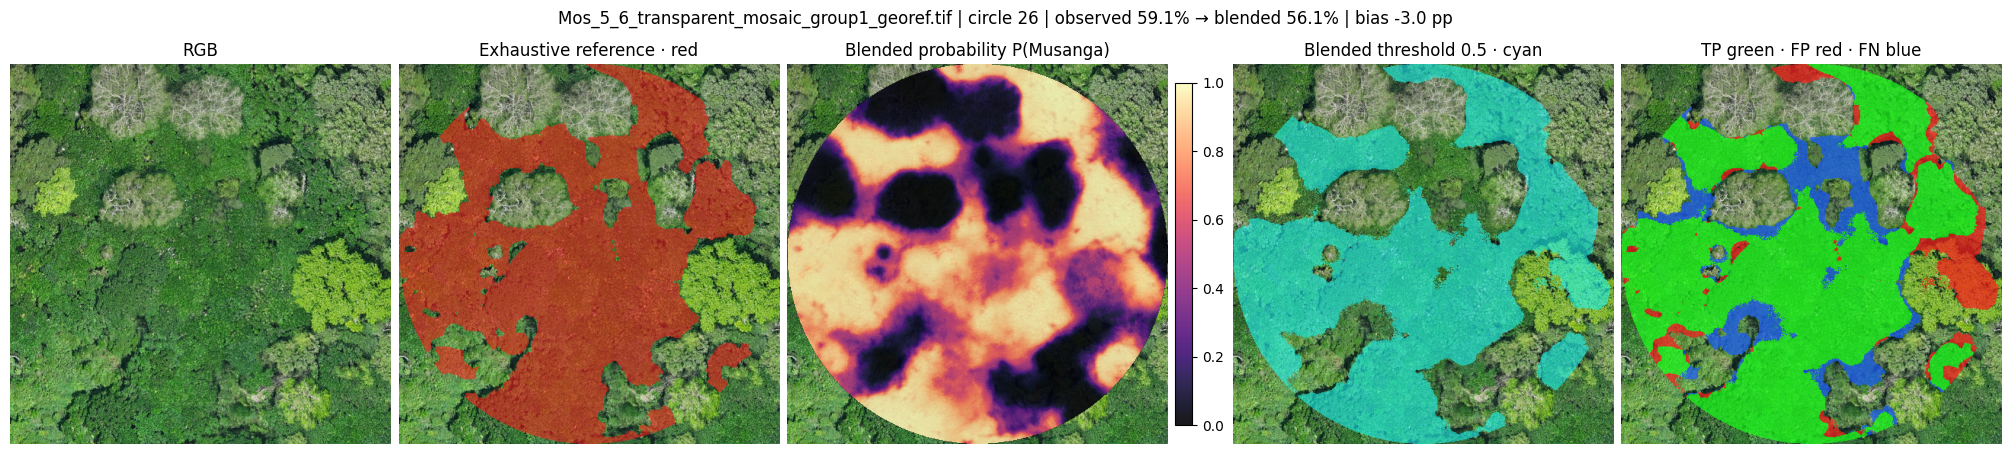

CIRCLE 27 fold 0 obs 17.24 blended 23.2 F1 0.566
CIRCLE 28 fold 0 obs 4.08 blended 6.52 F1 0.358
CIRCLE 29 fold 0 obs 2.19 blended 14.78 F1 0.138


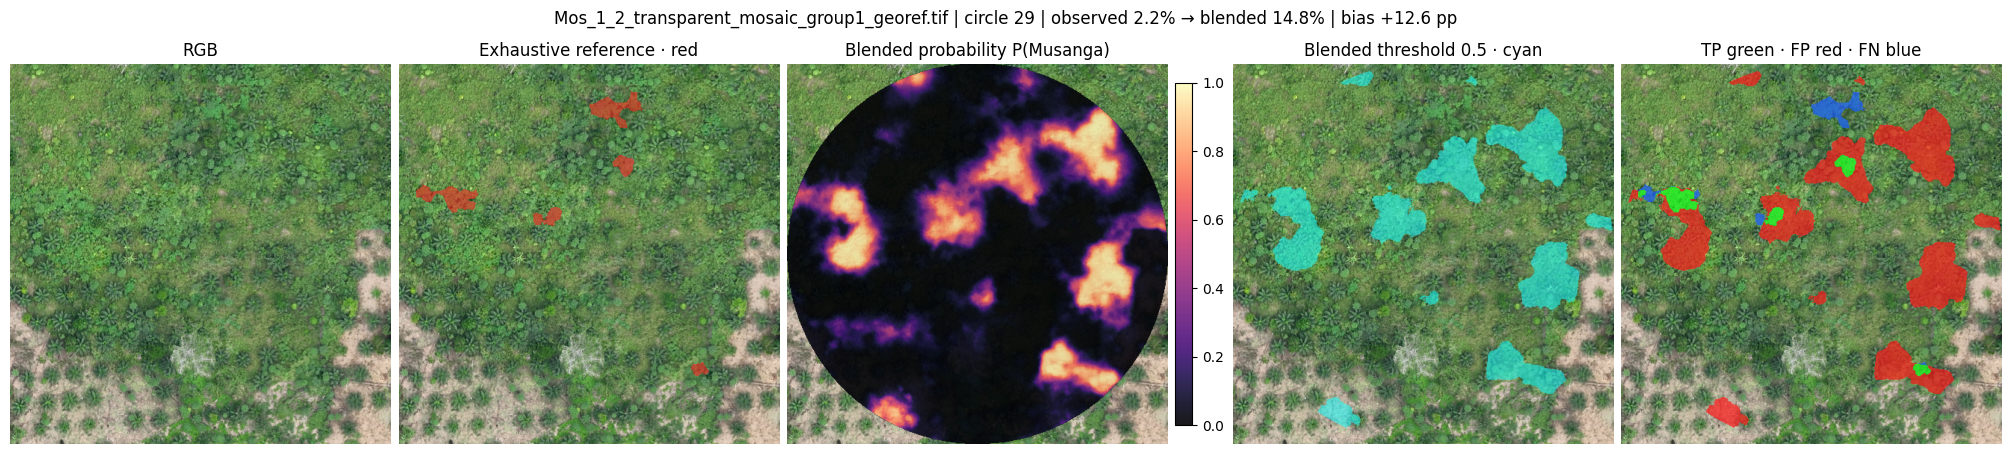

CIRCLE 32 fold 0 obs 18.69 blended 23.61 F1 0.691
CIRCLE 33 fold 0 obs 7.47 blended 11.94 F1 0.581
CIRCLE 3 fold 1 obs 54.93 blended 3.41 F1 0.117


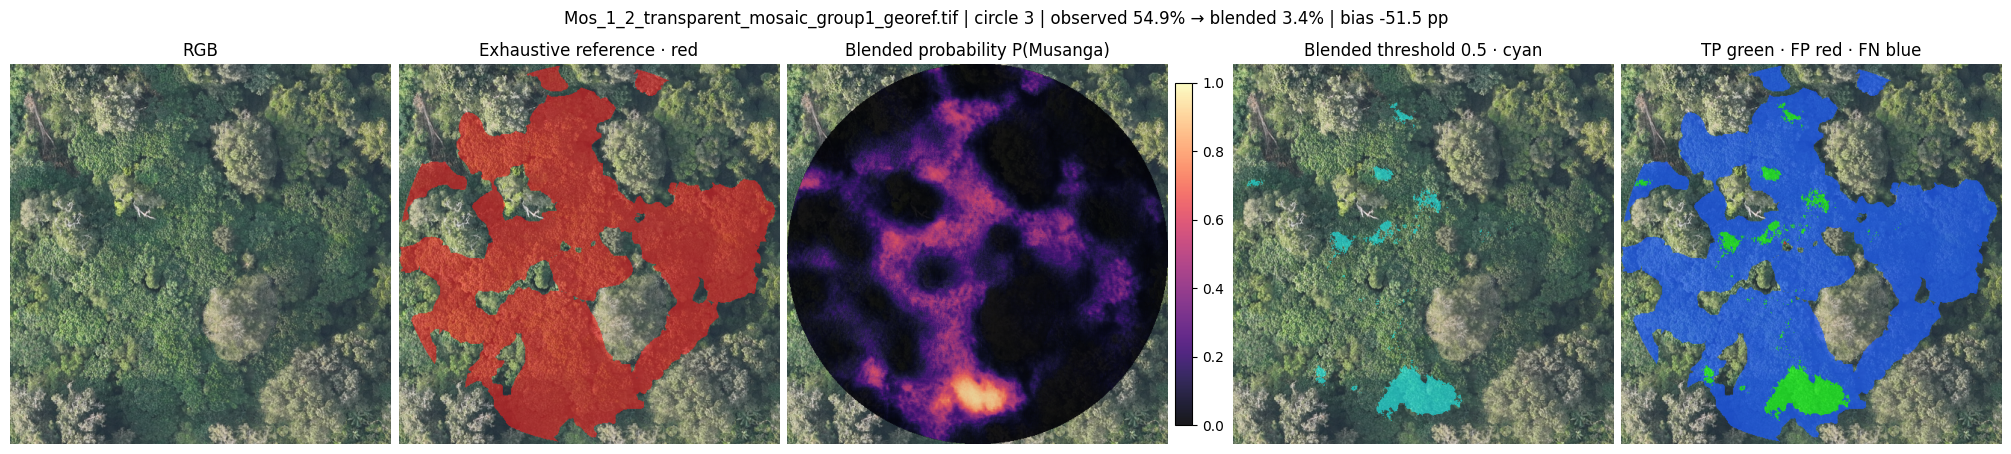

CIRCLE 4 fold 1 obs 4.24 blended 4.09 F1 0.504
CIRCLE 7 fold 1 obs 45.73 blended 50.38 F1 0.849
CIRCLE 9 fold 1 obs 5.06 blended 26.04 F1 0.301


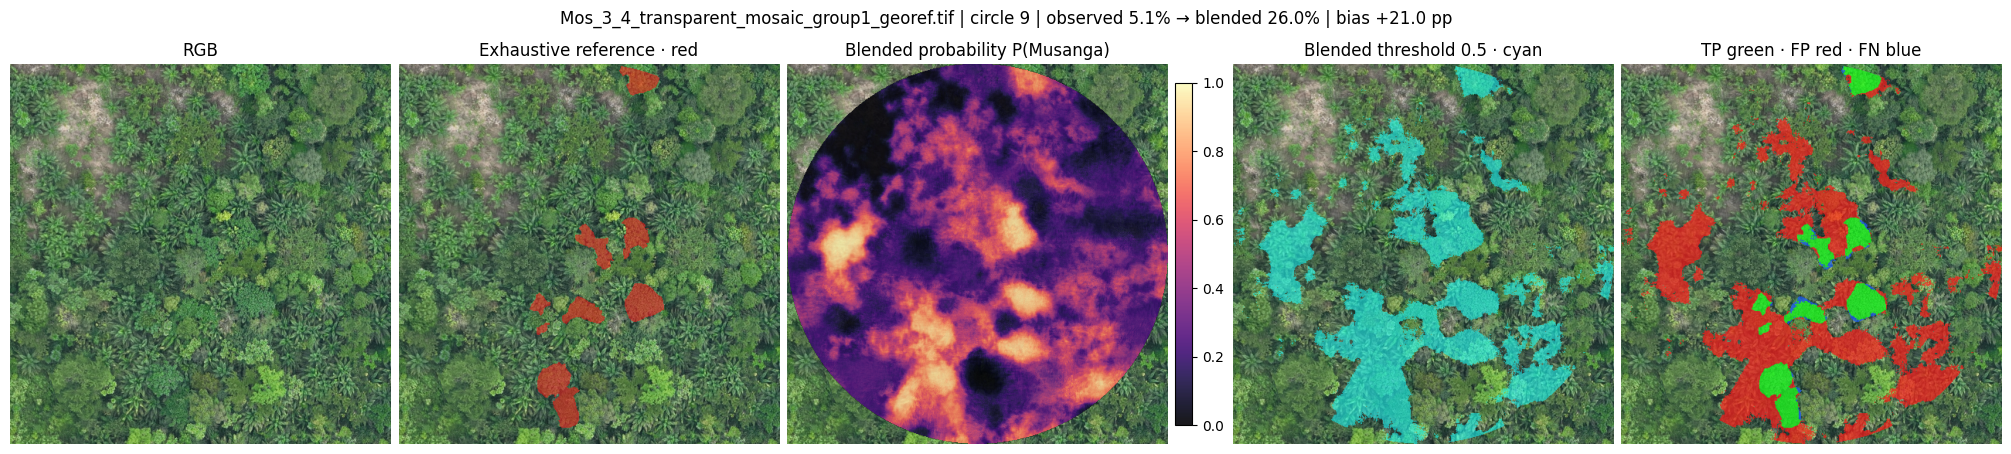

CIRCLE 11 fold 1 obs 1.82 blended 1.54 F1 0.415
CIRCLE 21 fold 1 obs 0.71 blended 8.75 F1 0.143
CIRCLE 23 fold 1 obs 14.86 blended 14.8 F1 0.636
CIRCLE 25 fold 1 obs 14.1 blended 7.61 F1 0.61
CIRCLE 30 fold 1 obs 1.8 blended 11.07 F1 0.26
CIRCLE 31 fold 1 obs 3.95 blended 4.66 F1 0.691
CIRCLE 0 fold 2 obs 45.24 blended 61.88 F1 0.798
CIRCLE 1 fold 2 obs 19.84 blended 31.09 F1 0.765
CIRCLE 5 fold 2 obs 38.36 blended 45.61 F1 0.85
CIRCLE 6 fold 2 obs 20.53 blended 23.26 F1 0.807
CIRCLE 13 fold 2 obs 2.96 blended 4.41 F1 0.635
CIRCLE 20 fold 2 obs 0.61 blended 3.26 F1 0.236
CIRCLE 22 fold 2 obs 8.84 blended 13.92 F1 0.73


,grouping,site,fold,n_units,cover_R2,cover_Pearson_r,cover_MAE_pp,cover_RMSE_pp,cover_bias_pp,cover_RPD,...,pooled_tn,pooled_pixel_precision,pooled_pixel_recall,pooled_pixel_specificity,pooled_pixel_balanced_accuracy,pooled_pixel_F1,pooled_pixel_IoU,pooled_pixel_prevalence,pixel_ROC_AUC_512bins,pixel_average_precision_512bins
0,ALL,ALL,ALL,34.0,0.537,0.779,6.491,11.280,2.070,1.492,...,191172479.0,0.490,0.707,0.958,0.832,0.579,0.408,0.055,0.923,0.656
1,site,Baego,ALL,7.0,0.514,0.986,8.458,9.833,8.458,1.550,...,9663137.0,0.613,0.906,0.877,0.892,0.731,0.576,0.177,0.953,0.865
2,site,MOS,ALL,15.0,0.323,0.636,8.835,15.338,-0.613,1.258,...,8615123.0,0.657,0.635,0.914,0.775,0.646,0.477,0.205,0.863,0.701
3,site,Yangambi,ALL,7.0,-45.755,-0.391,3.166,3.957,2.955,0.158,...,131171732.0,0.204,0.640,0.965,0.802,0.309,0.183,0.014,0.909,0.424
4,site,Yoko,ALL,5.0,0.987,0.996,1.359,1.470,-0.066,9.745,...,41722487.0,0.677,0.672,0.964,0.818,0.675,0.509,0.100,0.907,0.719
5,fold,ALL,0,17.0,0.867,0.945,4.206,5.522,2.247,2.824,...,125125083.0,0.528,0.684,0.963,0.824,0.596,0.424,0.057,0.931,0.664
6,fold,ALL,1,10.0,0.035,0.408,10.215,18.192,-1.485,1.073,...,34177986.0,0.271,0.533,0.940,0.736,0.359,0.219,0.040,0.859,0.279
7,fold,ALL,2,7.0,0.717,0.988,6.718,8.436,6.718,2.032,...,31869410.0,0.570,0.912,0.955,0.933,0.701,0.540,0.062,0.980,0.859
8,site_fold,Baego,0,3.0,0.004,0.986,7.112,7.894,7.112,1.227,...,4169311.0,0.609,0.855,0.883,0.869,0.712,0.552,0.176,0.941,0.817
9,site_fold,MOS,0,6.0,0.875,0.938,5.605,6.891,1.392,3.098,...,3619089.0,0.613,0.670,0.916,0.793,0.640,0.471,0.167,0.893,0.675


In [17]:
# All 34 circles, full native reference support, same 128 px global grid.
# This is the PRIMARY full-circle V4.009 evaluation (not optional).
MOSAIC_BY_CIRCLE={}
for cr in CIRCLE_ROI.itertuples(index=False):
    choices=[]
    for name,meta in RGB.items():
        if meta['site']!=cr.site_key:continue
        with rasterio.open(meta['path']) as ds:
            area=cr.geometry.intersection(box(*ds.bounds)).area
        if area>0:choices.append((area,name))
    assert choices,(cr.circle_id,'Missing mosaic')
    MOSAIC_BY_CIRCLE[int(cr.circle_id)]=max(choices)[1]
CIRCLE_ROWS=[]
for fold in FOLDS:
    model=load_frozen_model(fold)
    for cr in CIRCLE_ROI.loc[CIRCLE_ROI.cv_fold.eq(fold)].itertuples(index=False):
        cid=int(cr.circle_id);mosaic=MOSAIC_BY_CIRCLE[cid]
        with rasterio.open(RGB[mosaic]['path']) as ds:
            bound=rasterio.windows.from_bounds(*cr.geometry.bounds,transform=ds.transform)
            row=max(0,int(np.floor(bound.row_off)))
            col=max(0,int(np.floor(bound.col_off)))
            bottom=min(ds.height,int(np.ceil(bound.row_off+bound.height)))
            right=min(ds.width,int(np.ceil(bound.col_off+bound.width)))
            win=Window(col,row,right-col,bottom-row)
            bb=box(*rasterio.windows.bounds(win,ds.transform))
            mask=burn([cr.geometry],ds,win)
            roi=burn(geom_hits(ROI_T,ROI_GEOMS,bb),ds,win)
            valid=ds.dataset_mask(window=win)>0
            truth=burn(geom_hits(KPOS_T,CIRCLE_POS_GEOMS,bb),ds,win)
            support=mask&roi&valid
            assert support.any(),cid
            probs=blended_window(ds,model,win)
            metrics=collect_metrics(probs,truth,support)
            tot,positive=probability_histogram(probs[support],truth[support])
            CIRCLE_PROB_HISTS[cid]=(tot,positive)
            auc,ap=rank_scores(tot,positive)
            metrics.update(pixel_ROC_AUC_512bins=auc,
                           pixel_average_precision_512bins=ap)
            metrics.update(circle_id=cid,fold=fold,site=cr.site_key,mosaic=mosaic,
                           valid_support_pct=100*support.sum()/max(1,mask.sum()),
                           centre_E=float(cr.geometry.centroid.x),
                           centre_N=float(cr.geometry.centroid.y))
            CIRCLE_ROWS.append(metrics)
            print('CIRCLE',cid,'fold',fold,'obs',round(metrics['observed_cover_pct'],2),
                  'blended',round(metrics['predicted_cover_pct'],2),
                  'F1',round(metrics['pixel_F1'],3),flush=True)
            if cid in EXAMPLE_IDS and SAVE_EXAMPLE_FIGURES:
                rgb=ds.read([1,2,3],window=win).astype('float32')/255.
                _figure(cid,mosaic,ds,win,rgb,truth,support,probs,metrics)
    del model
    torch.cuda.empty_cache();gc.collect()
CIRCLES_V009=pd.DataFrame(CIRCLE_ROWS).sort_values('circle_id')
assert len(CIRCLES_V009)==34 and CIRCLES_V009.circle_id.is_unique
CIRCLES_V009.to_csv(EVAL_OUT/'V4_009_full34_blended_circles.csv',index=False)
CIRCLE_METRICS=metrics_table(CIRCLES_V009,'circles',CIRCLE_PROB_HISTS,'circle_id')
save_histograms(EVAL_OUT/'V4_009_circle_probability_histograms_512bins.npz',CIRCLE_PROB_HISTS)
CIRCLE_METRICS.to_csv(EVAL_OUT/'V4_009_circle_metrics_by_site.csv',index=False)
display(CIRCLE_METRICS.round(3))


## 09 — Summaries and paired non-overlap versus overlap comparisons

Uses saved V4.007 results strictly as historical baseline. New metrics are computed only from V4.009 50% overlapping inference.


34 circles: MAE old 5.843 → blended 6.491
76 evaluable plots: paired output saved.


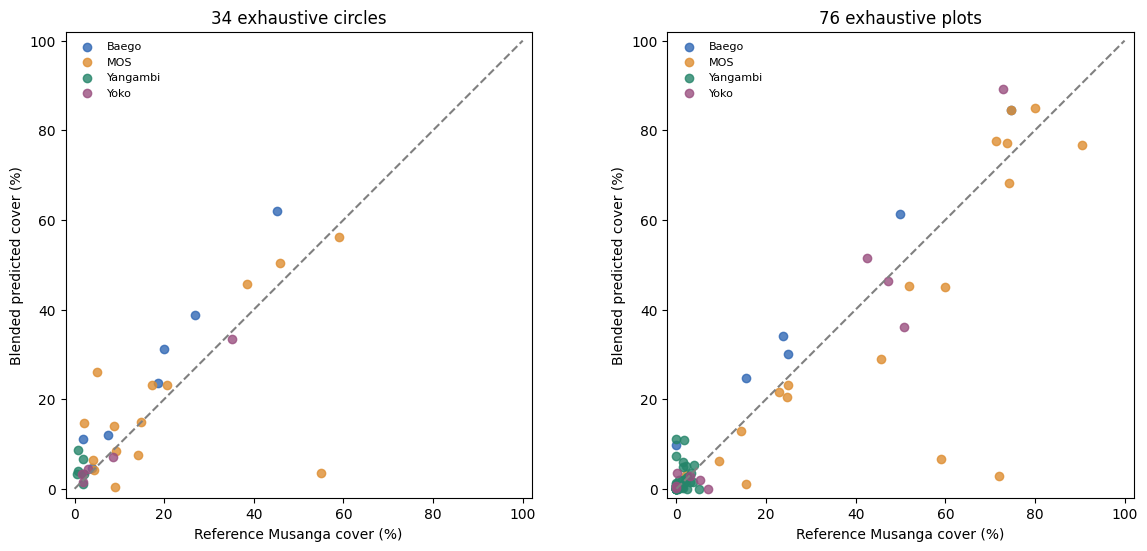

In [18]:
# Compare against original V4.007 evaluation summaries, where available.
OLD_DIR=ROOT/'Outputs/v4/02_rgb_unet_field78_v4_007_full'
old34=OLD_DIR/'performance_report/circles_full_v3style/02_v4_full34_circles_by_circle.csv'
old78=OLD_DIR/'02_rgb_heldout_per_plot.csv'
if old34.is_file():
    old=pd.read_csv(old34)
    paired=CIRCLES_V009.merge(old[['circle_id','predicted_fraction']],
                             on='circle_id',validate='one_to_one')
    paired['old_abs_err']=abs(paired.predicted_fraction-paired.observed_cover_pct)
    paired['new_abs_err']=abs(paired.predicted_cover_pct-paired.observed_cover_pct)
    paired.to_csv(EVAL_OUT/'V4_009_circle_paired_original_vs_blended.csv',index=False)
    print('34 circles: MAE old',round(paired.old_abs_err.mean(),3),
          '→ blended',round(paired.new_abs_err.mean(),3))
if old78.is_file():
    old=pd.read_csv(old78)
    paired=PLOTS_V009.merge(old[['Plot_name','predicted_cover_pct']],
                            on='Plot_name',suffixes=('_new','_old'),validate='one_to_one')
    paired.to_csv(EVAL_OUT/'V4_009_plot_paired_original_vs_blended.csv',index=False)
    print('76 evaluable plots: paired output saved.')
fig,ax=plt.subplots(1,2,figsize=(12,5.4),layout='constrained')
palette={'Baego':'#3168B4','MOS':'#DE8E32','Yangambi':'#25856A','Yoko':'#9A5080'}
for i,(frame,title) in enumerate([(CIRCLES_V009,'34 exhaustive circles'),
                                   (PLOTS_V009[PLOTS_V009.n_valid>0],'76 exhaustive plots')]):
    for site,d in frame.groupby('site'):
        ax[i].scatter(d.observed_cover_pct,d.predicted_cover_pct,
                      label=site,color=palette[site],alpha=.8,s=36)
    ax[i].plot([0,100],[0,100],'--',color='.5')
    ax[i].set(xlim=(-2,102),ylim=(-2,102),aspect='equal',
       xlabel='Reference Musanga cover (%)',ylabel='Blended predicted cover (%)',
       title=title)
    ax[i].legend(frameon=False,fontsize=8)
fig.savefig(EVAL_OUT/'V4_009_full_blended_scatterplots.png',dpi=200,bbox_inches='tight')
plt.show();plt.close(fig)
